# SPiCe Tutorial: Modelling Epithelial-Mesenchymal Plasticity

This notebook demonstrates the full SPiCe workflow for breast cancer Xenium
spatial transcriptomics data using the `spice.tl` / `spice.pl` API.

All tool functions modify `adata` in place — results are stored in
`adata.obs`, `adata.obsm` and `adata.uns['spice']`.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import enrichmap as em
import spice

In [4]:
sc.set_figure_params(frameon=False)

In [5]:
project_dir = "/home/cenk/Withnell_spice/"
os.chdir(project_dir)

figures_dir = project_dir +"figures/"

## 1. Load data into AnnData

In [6]:
adata = sc.read_h5ad("processed_data/xenium_v1_hallmark_spice_results.h5ad")

In [7]:
x_pca = pd.read_csv("SPiCe_original/source_data/X_pca_df.csv", index_col=0)
x_pca = x_pca[["cell_id"] + [col for col in x_pca.columns if col.startswith("PC")]]
x_pca.index = x_pca["cell_id"]
x_pca = x_pca.drop(columns=["cell_id"])
x_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
cell_id,,,,,,,
1182,-0.362636,13.854070,-7.168869,2.618001,-4.204397,0.61705,-0.018872
1187,-0.362636,13.854070,-7.168869,2.618001,-4.204397,0.61705,-0.018872
1188,-0.362636,13.854070,-7.168869,2.618001,-4.204397,0.61705,-0.018872
1190,-0.362636,13.854070,-7.168869,2.618001,-4.204397,0.61705,-0.018872
1222,-8.173728,-3.148516,1.467361,2.046034,-1.003653,0.03579,-0.008762


In [8]:
adata.obsm["X_pca"] = (
    adata.obs[["cell_id"]]
    .merge(x_pca, left_on="cell_id", right_index=True, how="left")
    .drop(columns="cell_id")
    .values
)

In [9]:
spice.tl.build_graph(adata, celltype_key="celltype_minor", score_key="EMT_score")

In [10]:
spice.tl.cross_validate(adata, feature_mode="combined")


Fold 1/5


  Epoch    0 | Loss 0.3468 | Test AUC: 0.5841


  Epoch  100 | Loss 0.2511 | Test AUC: 0.8022


  Epoch  200 | Loss 0.2452 | Test AUC: 0.8085


  Epoch  300 | Loss 0.2428 | Test AUC: 0.8095


  Epoch  400 | Loss 0.2424 | Test AUC: 0.8102


... (21 outputs left out)

  Epoch  200 | Loss 0.2379 | Test AUC: 0.7779


  Epoch  300 | Loss 0.2354 | Test AUC: 0.7750


  Epoch  400 | Loss 0.2349 | Test AUC: 0.7767


  Epoch  499 | Loss 0.2337 | Test AUC: 0.7769

Mean performance: 0.7969 ± 0.0190


In [11]:
spice.tl.evaluate(adata)

(<Figure size 400x280 with 1 Axes>, <Axes: ylabel='AUC'>)

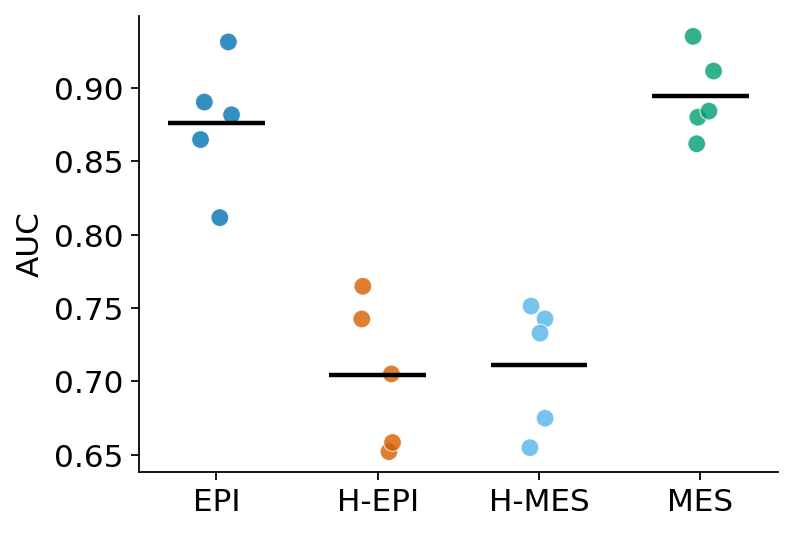

In [12]:
EMT_MAP = {"0": "EPI", "1": "H-EPI", "2": "H-MES", "3": "MES"}
spice.pl.auc_per_class(
    adata, state_map=EMT_MAP, save=figures_dir + "xenium_v1_auc_per_class_hallmark_combined.pdf"
)

In [13]:
spice.tl.explain_nodes(adata, n_explanations=300)

Computing node explanations for label 0...


Label 0:   0%|          | 0/300 [00:00<?, ?it/s]

Label 0:   1%|          | 3/300 [00:16<27:38,  5.58s/it]

Label 0:   3%|▎         | 8/300 [00:33<19:33,  4.02s/it]

Label 0:   3%|▎         | 10/300 [00:50<25:36,  5.30s/it]

Label 0:   4%|▎         | 11/300 [01:07<35:11,  7.31s/it]

... (990 outputs left out)

Permutation:  99%|█████████▉| 298/300 [1:28:15<00:33, 17.00s/it]

Permutation: 100%|█████████▉| 299/300 [1:28:32<00:16, 16.98s/it]

Permutation: 100%|██████████| 300/300 [1:28:49<00:00, 16.92s/it]

Permutation: 100%|██████████| 300/300 [1:28:49<00:00, 17.76s/it]

(<Figure size 1040x640 with 4 Axes>,
 array([<Axes: title={'center': 'EPI'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'H-EPI'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'H-MES'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'MES'}, ylabel='$-\\log_{10}(p)$'>],
       dtype=object))

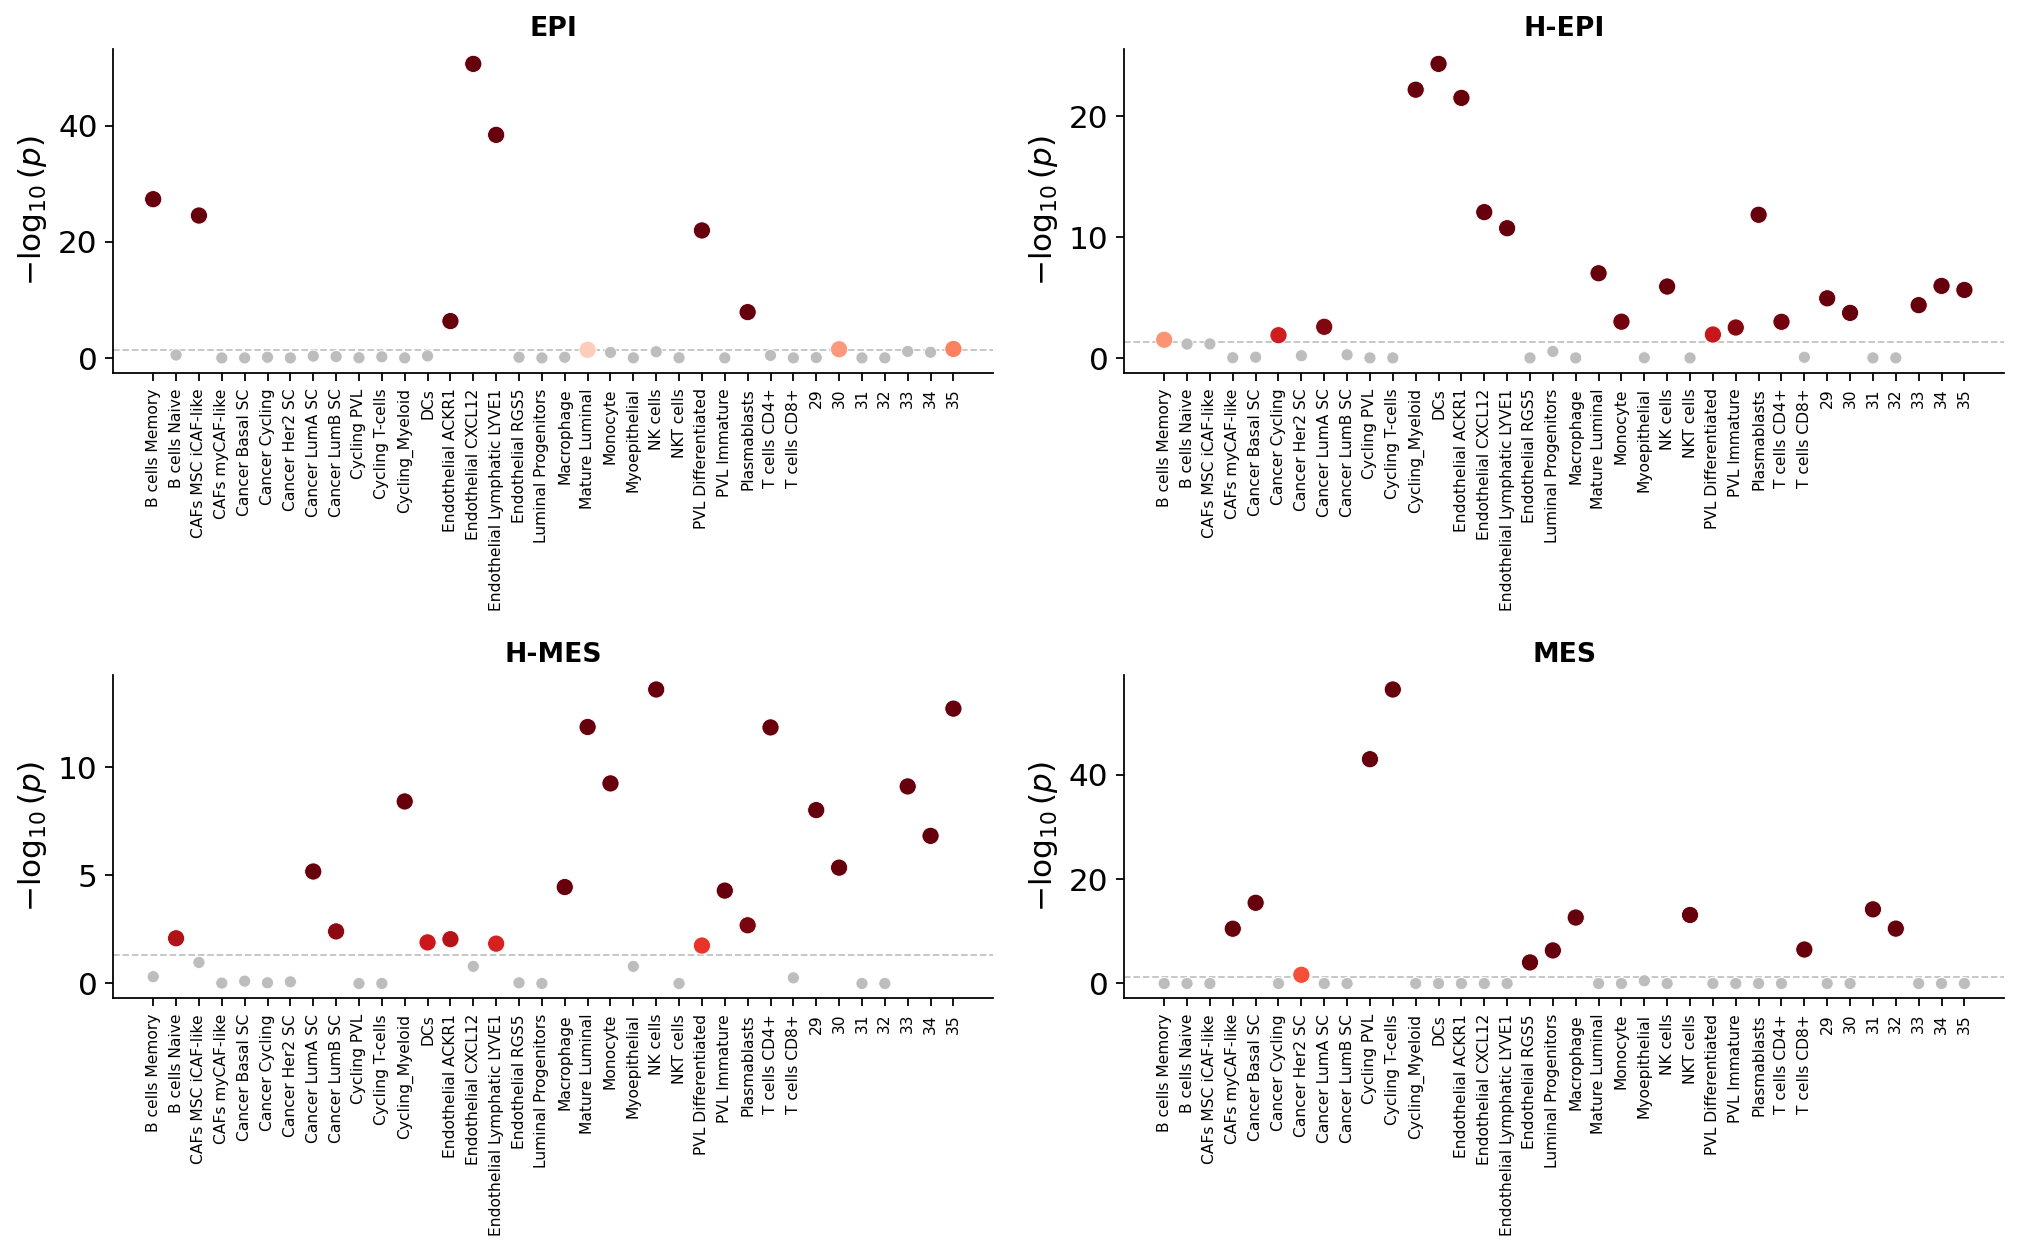

In [14]:
spice.pl.node_importance(
    adata,
    state_map={0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"},
    save="xenium_v1_hallmark_node_importance.pdf"
)

In [15]:
spice.tl.explain_edges(adata, n_explanations=300)

Edge explanations for label 0...


Label 0:   0%|          | 0/600 [00:00<?, ?it/s]

Label 0:   0%|          | 1/600 [01:42<17:06:17, 102.80s/it]

Label 0:   0%|          | 2/600 [03:21<16:38:06, 100.15s/it]

Label 0:   0%|          | 3/600 [04:58<16:23:10, 98.81s/it] 

Label 0:   1%|          | 4/600 [06:36<16:18:54, 98.55s/it]

... (2,402 outputs left out)

Label 3: 100%|█████████▉| 598/600 [11:19:53<03:26, 103.10s/it]

Label 3: 100%|█████████▉| 599/600 [11:21:35<01:42, 102.66s/it]

Label 3: 100%|██████████| 600/600 [11:23:19<00:00, 103.15s/it]

Label 3: 100%|██████████| 600/600 [11:23:19<00:00, 68.33s/it] 

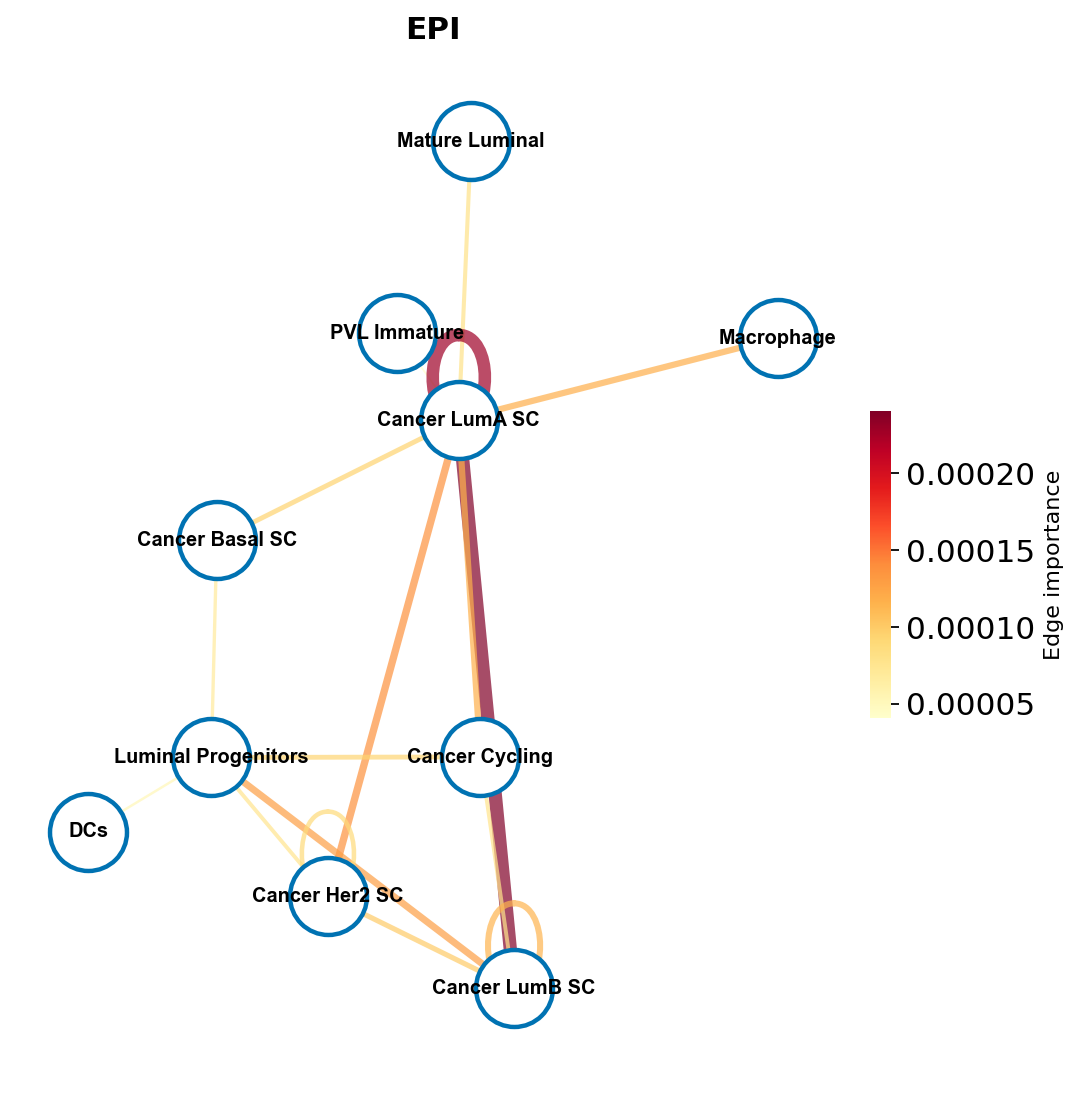

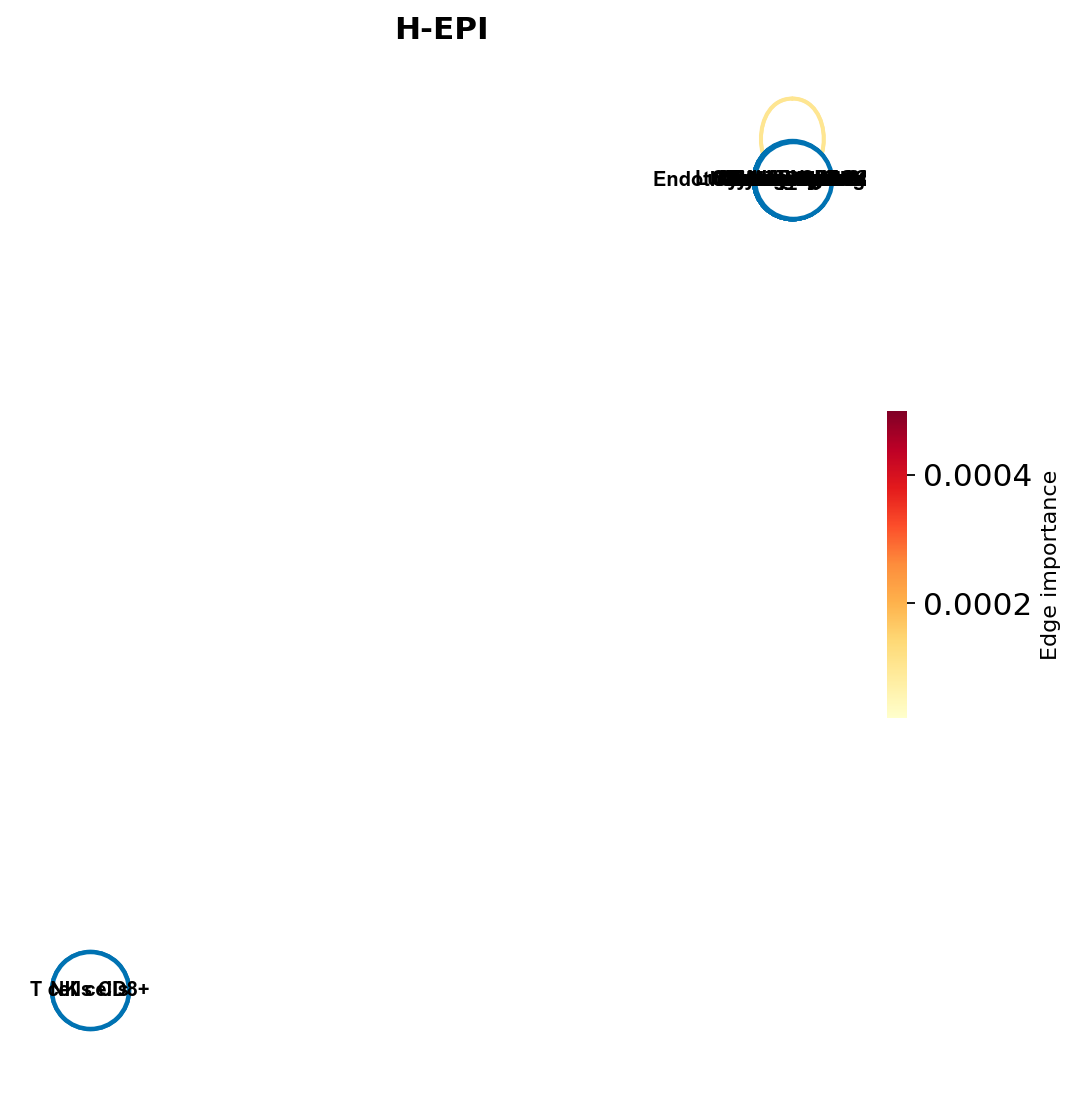

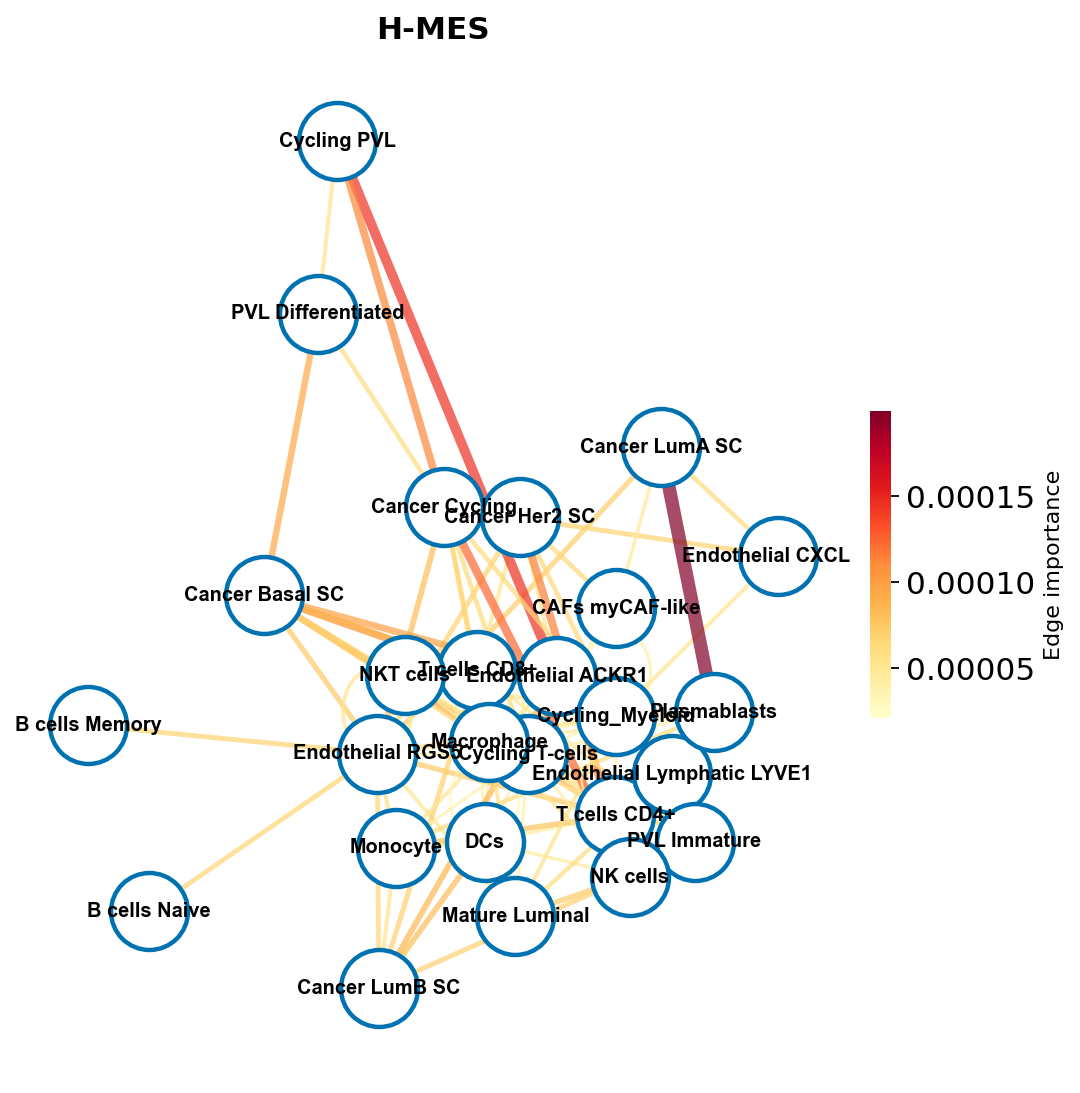

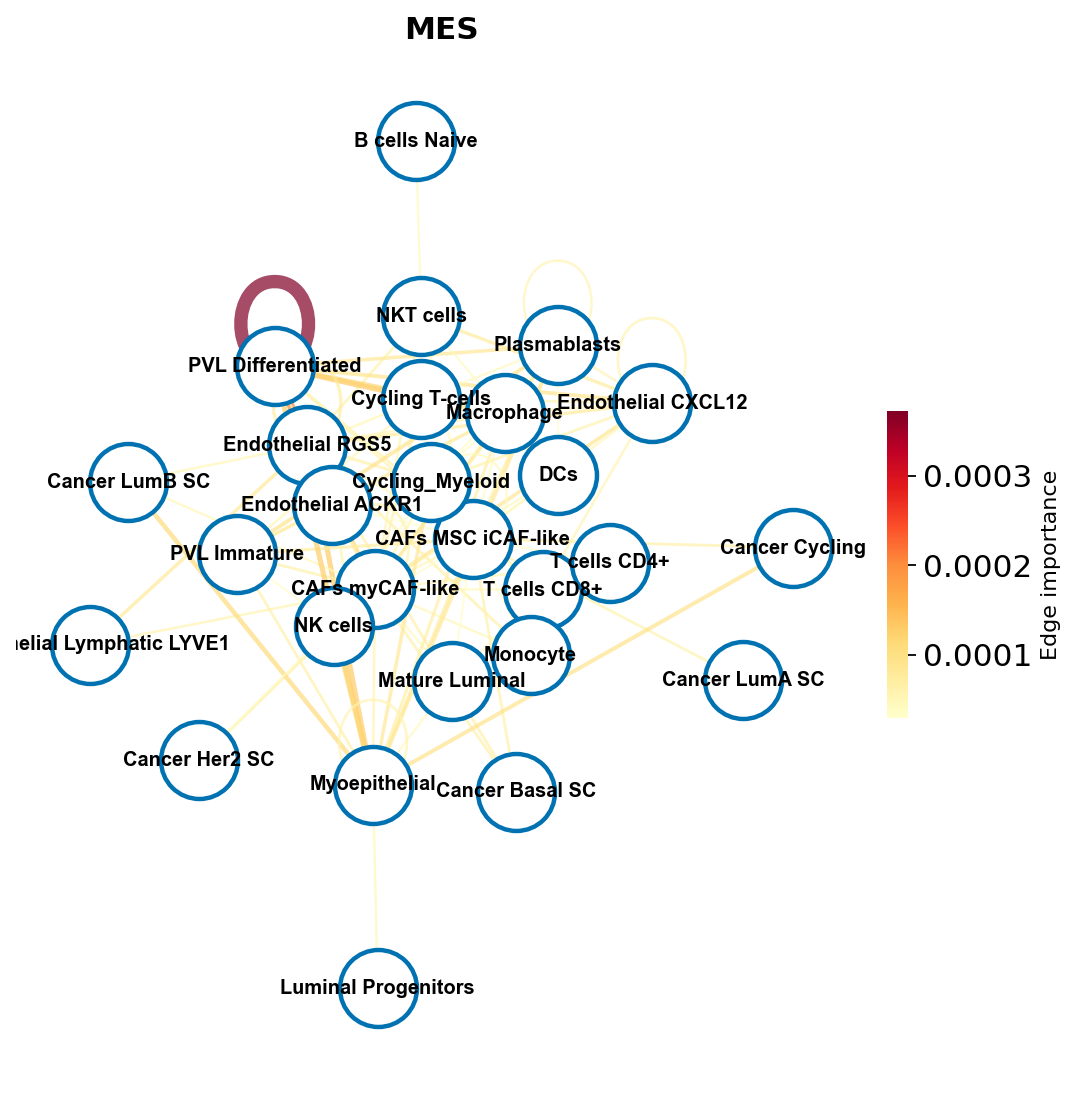

In [16]:
spice.pl.edge_network(
    adata,
    state_map={0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"},
    save="xenium_v1_hallmark_edge_importance.pdf",
)